# EDA Parte 1 – Estructura, calidad y estadística (Miguel)
**Proyecto BI – Purchasing | Sprint 1**

Contenido:
1. Carga de datos (solo CSV locales)
2. Estructura de las tablas
3. Calidad de datos (nulos, duplicados, anomalías)
4. Outliers (IQR)
5. Análisis estadístico
6. Matriz de correlación
7. Tabla de calidad y decisiones de limpieza (para Molina)

In [11]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None); pd.set_option("display.float_format", "{:,.2f}".format)

ROOT = Path("..") if Path("../data").exists() else Path(".")
RAW, PROC = ROOT/"data/raw", ROOT/"data/processed"

tablas = {
    "Vendor": pd.read_csv(RAW/"vendor.csv"),
    "PurchaseOrderHeader": pd.read_csv(RAW/"purchase_order_header.csv"),
    "PurchaseOrderDetail": pd.read_csv(RAW/"purchase_order_detail.csv"),
    "ProductVendor": pd.read_csv(RAW/"product_vendor.csv"),
}
consol = pd.read_csv(PROC/"purchasing_consolidated.csv")

def col(df, nombre):
    """Busca una columna sin importar mayúsculas."""
    for c in df.columns:
        if c.lower() == nombre.lower(): return c
    return None

## 1. Estructura de los datos

In [12]:
resumen = pd.DataFrame({t: {"Filas": d.shape[0], "Columnas": d.shape[1]} for t, d in tablas.items()}).T
resumen.loc["Consolidado (por vendor)"] = consol.shape
display(resumen)
for t, d in {**tablas, "Consolidado": consol}.items():
    print(f"\n=== {t} ===")
    display(pd.DataFrame({"Tipo": d.dtypes.astype(str), "No nulos": d.notna().sum(), "Nulos": d.isna().sum()}))

,Filas,Columnas
Vendor,106,5
PurchaseOrderHeader,4019,13
PurchaseOrderDetail,8853,11
ProductVendor,467,11
Consolidado (por vendor),106,15



=== Vendor ===


,Tipo,No nulos,Nulos
BusinessEntityID,int64,106,0
Name,str,106,0
CreditRating,int64,106,0
PreferredVendorStatus,bool,106,0
ActiveFlag,bool,106,0



=== PurchaseOrderHeader ===


,Tipo,No nulos,Nulos
PurchaseOrderID,int64,4019,0
RevisionNumber,int64,4019,0
Status,int64,4019,0
EmployeeID,int64,4019,0
VendorID,int64,4019,0
ShipMethodID,int64,4019,0
OrderDate,str,4019,0
ShipDate,str,4019,0
SubTotal,float64,4019,0
TaxAmt,float64,4019,0


...

,Tipo,No nulos,Nulos
PurchaseOrderID,int64,8853,0
PurchaseOrderDetailID,int64,8853,0
DueDate,str,8853,0
OrderQty,int64,8853,0
ProductID,int64,8853,0
UnitPrice,float64,8853,0
LineTotal,float64,8853,0
ReceivedQty,float64,8853,0
RejectedQty,float64,8853,0
StockedQty,float64,8853,0



=== ProductVendor ===


,Tipo,No nulos,Nulos
ProductID,int64,467,0
BusinessEntityID,int64,467,0
AverageLeadTime,int64,467,0
StandardPrice,float64,467,0
LastReceiptCost,float64,460,7
LastReceiptDate,str,460,7
MinOrderQty,int64,467,0
MaxOrderQty,int64,467,0
OnOrderQty,float64,156,311
UnitMeasureCode,str,467,0



=== Consolidado ===


,Tipo,No nulos,Nulos
VendorID,int64,106,0
NombreProveedor,str,106,0
CreditRating,int64,106,0
PreferredVendorStatus,bool,106,0
ActiveFlag,bool,106,0
NumeroOrdenes,float64,88,18
ValorTotalOrdenes,float64,88,18
GastoPromedioOrden,float64,88,18
UltimaOrden,str,88,18
UnidadesPedidas,float64,88,18


**Conclusión:** El dataset está compuesto por 4 tablas del esquema Purchasing: Vendor (106 filas × 5 columnas), PurchaseOrderHeader (4,019 × 13), PurchaseOrderDetail (8,853 × 11) y ProductVendor (467 × 11). El consolidado por proveedor tiene 106 filas × 15 columnas (una fila por vendor). Los tipos de dato son coherentes: identificadores y conteos como `int64`, montos y precios como `float64` y banderas como `bool`.

Observaciones:
1. Todas las columnas de fecha (OrderDate, ShipDate, DueDate, ModifiedDate, LastReceiptDate, UltimaOrden) están como texto (`str`) y habría que convertirlas a `datetime` para cualquier análisis temporal.
2. El identificador del proveedor se llama `BusinessEntityID` en Vendor y ProductVendor, pero `VendorID` en PurchaseOrderHeader y en el consolidado; los joins se hacen entre columnas con nombres distintos.

## 2. Calidad de datos

### 2.1 Valores faltantes y duplicados

In [13]:
calidad = []
for t, d in {**tablas, "Consolidado": consol}.items():
    for c, n in d.isna().sum().items():
        if n > 0: calidad.append([t, f"Valores faltantes en {c}", n, n/len(d)*100])
    nd = d.duplicated().sum()
    if nd > 0: calidad.append([t, "Filas duplicadas", nd, nd/len(d)*100])
display(pd.DataFrame(calidad, columns=["Tabla","Problema","Cantidad","% de filas"]))

,Tabla,Problema,Cantidad,% de filas
0,ProductVendor,Valores faltantes en LastReceiptCost,7,1.50
1,ProductVendor,Valores faltantes en LastReceiptDate,7,1.50
2,ProductVendor,Valores faltantes en OnOrderQty,311,66.60
3,Consolidado,Valores faltantes en NumeroOrdenes,18,16.98
4,Consolidado,Valores faltantes en ValorTotalOrdenes,18,16.98
5,Consolidado,Valores faltantes en GastoPromedioOrden,18,16.98
6,Consolidado,Valores faltantes en UltimaOrden,18,16.98
7,Consolidado,Valores faltantes en UnidadesPedidas,18,16.98
8,Consolidado,Valores faltantes en ProductosComprados,18,16.98
9,Consolidado,Valores faltantes en ValorLineas,18,16.98


**Conclusión:** Vendor, PurchaseOrderHeader y PurchaseOrderDetail no tienen valores faltantes ni filas duplicadas. En ProductVendor faltan 7 valores (1.50 %) en LastReceiptCost y LastReceiptDate (productos sin recepción registrada) y 311 (66.60 %) en OnOrderQty, que probablemente indica productos sin cantidad pendiente de pedido: es un nulo con significado de negocio, no un error.

En el consolidado, 18 vendors (16.98 %) tienen nulos en todas las métricas de compra porque existen en Vendor pero no tienen ninguna orden. Los faltantes de ProductVendor no afectan las variables del clustering (monto y número de órdenes); los 18 vendors sin órdenes sí, y se tratan en la sección 6.

### 2.2 Anomalías específicas

In [14]:
hdr = tablas["PurchaseOrderHeader"]
casos = []

td = col(hdr, "TotalDue")
if td:
    n = (hdr[td] <= 0).sum()
    print(f"Órdenes con TotalDue <= 0: {n}")
    casos.append(["PurchaseOrderHeader", "TotalDue <= 0", n, n/len(hdr)*100])

vend = tablas["Vendor"]; vid = col(vend, "VendorID") or col(vend, "BusinessEntityID")
pv = tablas["ProductVendor"]; pv_vid = col(pv, "VendorID") or col(pv, "BusinessEntityID")
sin_prod = vend[~vend[vid].isin(pv[pv_vid])]
print(f"Vendors sin productos asociados (no están en ProductVendor): {len(sin_prod)}")
casos.append(["Vendor", "Sin productos asociados", len(sin_prod), len(sin_prod)/len(vend)*100])

hdr_vid = col(hdr, "VendorID")
sin_ord = vend[~vend[vid].isin(hdr[hdr_vid])]
print(f"Vendors sin órdenes de compra: {len(sin_ord)}")
casos.append(["Vendor", "Sin órdenes de compra", len(sin_ord), len(sin_ord)/len(vend)*100])

em = col(vend, "EmailAddress") or col(vend, "Email")
if em:
    n = vend[em].isna().sum(); print(f"Vendors sin email: {n}")
    casos.append(["Vendor", "Sin email", n, n/len(vend)*100])
else:
    print("La tabla Vendor extraída no trae columna de email (vive en Person.EmailAddress, fuera del esquema Purchasing).")

anom = pd.DataFrame(casos, columns=["Tabla","Problema","Cantidad","% de filas"]); display(anom)

Órdenes con TotalDue <= 0: 1
Vendors sin productos asociados (no están en ProductVendor): 18
Vendors sin órdenes de compra: 18
La tabla Vendor extraída no trae columna de email (vive en Person.EmailAddress, fuera del esquema Purchasing).


,Tabla,Problema,Cantidad,% de filas
0,PurchaseOrderHeader,TotalDue <= 0,1,0.02
1,Vendor,Sin productos asociados,18,16.98
2,Vendor,Sin órdenes de compra,18,16.98


**Conclusión:** Se detectó 1 orden con TotalDue ≤ 0 (0.02 % de las 4,019 órdenes); el impacto es insignificante, pero se documenta como anomalía. Además, 18 vendors (16.98 %) no tienen órdenes de compra y 18 no tienen productos asociados en ProductVendor (la celda 2.3 verifica si son los mismos). Estos vendors no se pueden segmentar por monto ni por número de órdenes, por lo que se excluyen del clustering. El email no se pudo evaluar porque la tabla Vendor del esquema Purchasing no lo incluye (vive en Person.EmailAddress).

### 2.3 Inspección de casos raros

In [22]:
# 2.3 Inspección de casos raros
print("Orden(es) con TotalDue <= 0:")
display(hdr[hdr["TotalDue"] <= 0])

mismos = set(sin_prod[vid]) == set(sin_ord[vid])
print("\n¿Los vendors sin productos son los mismos que no tienen órdenes?", mismos,
      "| en común:", len(set(sin_prod[vid]) & set(sin_ord[vid])))

print("\nRevisionNumber:"); display(hdr["RevisionNumber"].value_counts().sort_index())
print("Status:"); display(hdr["Status"].value_counts().sort_index())

f = hdr.assign(OrderDate=pd.to_datetime(hdr["OrderDate"]), ShipDate=pd.to_datetime(hdr["ShipDate"]))
print("\nÓrdenes con ShipDate < OrderDate:", (f["ShipDate"] < f["OrderDate"]).sum())
dif = (hdr["SubTotal"] + hdr["TaxAmt"] + hdr["Freight"] - hdr["TotalDue"]).abs()
print("Órdenes donde SubTotal + TaxAmt + Freight no coincide con TotalDue:", (dif > 0.01).sum())

Orden(es) con TotalDue <= 0:


,PurchaseOrderID,RevisionNumber,Status,EmployeeID,VendorID,ShipMethodID,OrderDate,ShipDate,SubTotal,TaxAmt,Freight,TotalDue,ModifiedDate
4012,6013,0,1,1,1492,1,2026-08-20,2026-08-25,0.00,0.00,0.00,0.00,2026-08-22 01:33:34.410



¿Los vendors sin productos son los mismos que no tienen órdenes? True | en común: 18

RevisionNumber:


RevisionNumber
0        2
1        3
2        2
5     3813
6      129
7       44
8       15
9        3
10       4
11       1
13       1
15       1
21       1
Name: count, dtype: int64

Status:


Status
1     233
2      12
3      86
4    3688
Name: count, dtype: int64


Órdenes con ShipDate < OrderDate: 0
Órdenes donde SubTotal + TaxAmt + Freight no coincide con TotalDue: 0


**Conclusión:** La única orden con TotalDue ≤ 0 es la 6013 (vendor 1492), en estado Pending (Status = 1), con RevisionNumber 0 y SubTotal, impuestos y flete en 0, y con fecha de 2026, fuera del rango del resto de datos. Es una orden pendiente sin valor, no una compra real. Los 18 vendors sin productos son exactamente los mismos 18 sin órdenes. RevisionNumber es un contador de revisiones: el 95 % de las órdenes tiene valor 5 y el resto va de 0 a 21, sin impacto en el análisis. Status muestra 3,688 órdenes completas (Complete), 233 pendientes, 86 rechazadas y 12 aprobadas. No hay órdenes con ShipDate anterior a OrderDate, y SubTotal + TaxAmt + Freight coincide con TotalDue en todas.

## 3. Outliers (método IQR)

In [16]:
def iqr_outliers(d, nombre):
    filas = []
    for c in d.select_dtypes("number").columns:
        if c.lower().endswith("id") or d[c].nunique() < 3: continue
        q1, q3 = d[c].quantile([.25, .75]); i = q3 - q1
        lo, hi = q1 - 1.5*i, q3 + 1.5*i
        n = ((d[c] < lo) | (d[c] > hi)).sum()
        filas.append([nombre, c, q1, q3, i, lo, hi, n, n/d[c].notna().sum()*100])
    return pd.DataFrame(filas, columns=["Tabla","Variable","Q1","Q3","IQR","Límite inf","Límite sup","Outliers","% outliers"])

out = pd.concat([iqr_outliers(d, t) for t, d in {**tablas, "Consolidado": consol}.items()])
display(out)

,Tabla,Variable,Q1,Q3,IQR,Límite inf,Límite sup,Outliers,% outliers
0,Vendor,CreditRating,1.00,1.00,0.00,1.00,1.00,22,20.75
0,PurchaseOrderHeader,RevisionNumber,5.00,5.00,0.00,5.00,5.00,206,5.13
1,PurchaseOrderHeader,Status,4.00,4.00,0.00,4.00,4.00,331,8.24
2,PurchaseOrderHeader,SubTotal,383.20,"28,199.33","27,816.13","-41,340.99","69,923.52",89,2.21
3,PurchaseOrderHeader,TaxAmt,31.17,"2,255.95","2,224.77","-3,305.99","5,593.11",89,2.21
4,PurchaseOrderHeader,Freight,9.74,704.98,695.24,"-1,033.12","1,747.85",89,2.21
5,PurchaseOrderHeader,TotalDue,423.43,"31,160.25","30,736.82","-45,681.80","77,265.49",89,2.21
0,PurchaseOrderDetail,OrderQty,3.00,550.00,547.00,-817.50,"1,370.50",14,0.16
1,PurchaseOrderDetail,UnitPrice,25.42,45.44,20.02,-4.61,75.48,101,1.14
2,PurchaseOrderDetail,LineTotal,130.13,"14,882.17","14,752.05","-21,997.95","37,010.25",113,1.28


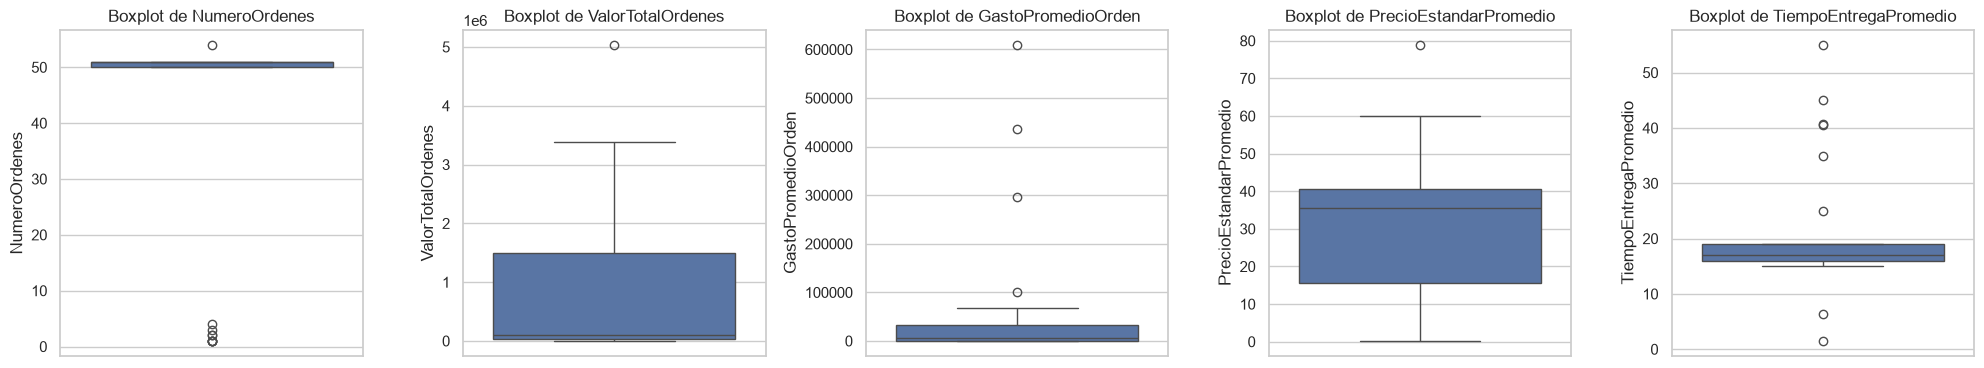

In [17]:
vars_box = [c for c in ["NumeroOrdenes","ValorTotalOrdenes","GastoPromedioOrden","PrecioEstandarPromedio","TiempoEntregaPromedio"] if c in consol.columns]
fig, axes = plt.subplots(1, len(vars_box), figsize=(4*len(vars_box), 4))
for ax, c in zip(np.atleast_1d(axes), vars_box):
    sns.boxplot(y=consol[c], ax=ax, color="#4C72B0"); ax.set_title(f"Boxplot de {c}"); ax.set_ylabel(c)
plt.tight_layout(); plt.show()

**Conclusión:** Con el método IQR (valores fuera de [Q1 − 1.5·IQR, Q3 + 1.5·IQR]):

- **Falsos outliers.** CreditRating (20.75 %), RevisionNumber, Status y RejectedQty aparecen con muchos outliers solo porque su IQR es 0 (casi todos los valores son iguales). Son variables categóricas o casi constantes, no datos anómalos.
- **Variables de monto en el consolidado.** ValorTotalOrdenes tiene 1 outlier (1.14 %), pero con una dispersión enorme: mediana ≈ 102 mil, Q3 ≈ 1.49 millones y máximo ≈ 5.03 millones. GastoPromedioOrden tiene 4 outliers (4.55 %), con máximo cercano a 609 mil. Los boxplots muestran asimetría a la derecha: pocos vendors concentran los montos más altos.
- **NumeroOrdenes.** El 50 % central de los vendors tiene entre 50 y 51 órdenes (Q1 = 50, Q3 = 51). Los 10 outliers (11.36 %) son vendors con muy pocas órdenes (en el gráfico, la mayoría entre 1 y 4). Esta variable casi no varía en la mayoría de los vendors.
- **Otras variables.** TiempoEntregaPromedio tiene 8 outliers en ambos extremos (de 1.5 a 55 días, con la mayoría entre 15 y 19). ProductosComprados y ProductosOfrecidos tienen 6 cada una (6.82 %). PrecioEstandarPromedio tiene 1.
- **PurchaseOrderHeader.** SubTotal, TaxAmt, Freight y TotalDue tienen 89 outliers (2.21 %) cada una, con máximos de hasta ≈ 1.1 millones.

Los outliers de monto no son errores: son vendors y órdenes grandes legítimos. **No se eliminan**, porque representan el segmento "Grandes" que K-Means debe identificar.

## 4. Análisis estadístico

In [18]:
def estadisticos(d):
    num = d.select_dtypes("number"); num = num[[c for c in num.columns if not c.lower().endswith("id")]]
    e = pd.DataFrame({
        "Media": num.mean(), "Mediana": num.median(),
        "Moda": num.mode().iloc[0] if len(num.mode()) else np.nan,
        "Mín": num.min(), "P5": num.quantile(.05), "Q1 (P25)": num.quantile(.25),
        "Q3 (P75)": num.quantile(.75), "P95": num.quantile(.95), "Máx": num.max(),
        "IQR": num.quantile(.75) - num.quantile(.25),
        "Varianza": num.var(), "Desv. estándar": num.std()})
    return e
display(estadisticos(consol))
print("\nPurchaseOrderHeader:"); display(estadisticos(tablas["PurchaseOrderHeader"]))

,Media,Mediana,Moda,Mín,P5,Q1 (P25),Q3 (P75),P95,Máx,IQR,Varianza,Desv. estándar
CreditRating,1.39,1.00,1.00,1.00,1.00,1.00,1.00,3.00,5.00,0.00,0.75,0.87
NumeroOrdenes,45.67,51.00,51.00,1.00,1.35,50.00,51.00,51.00,54.00,1.00,222.45,14.91
ValorTotalOrdenes,"800,982.18","102,009.78","1,952,375.30",17.00,"5,167.89","25,603.70","1,491,743.72","2,742,056.42","5,034,266.74","1,466,140.02","1,147,562,547,276.09","1,071,243.46"
GastoPromedioOrden,"31,560.74","6,335.02","38,281.87",17.00,110.03,520.18,"31,978.38","66,910.04","609,422.00","31,458.21","7,186,925,120.19","84,775.73"
UnidadesPedidas,"26,689.22","17,300.00","28,050.00",3.00,150.00,553.50,"55,000.00","75,020.00","125,000.00","54,446.50","923,761,300.33","30,393.44"
ProductosComprados,5.30,2.00,1.00,1.00,1.00,1.00,7.50,19.00,30.00,6.50,42.14,6.49
ValorLineas,"724,910.62","92,316.55","1,766,855.48",15.00,"4,690.29","23,011.82","1,349,994.32","2,481,499.02","4,555,897.50","1,326,982.50","939,942,952,995.48","969,506.55"
ProductosOfrecidos,5.31,2.00,1.00,1.00,1.00,1.00,7.50,19.00,30.00,6.50,41.78,6.46
TiempoEntregaPromedio,18.33,17.00,19.00,1.50,15.00,16.00,19.00,31.50,55.00,3.00,47.15,6.87
PrecioEstandarPromedio,30.15,35.47,37.99,0.20,3.63,15.49,40.53,51.98,78.89,25.04,255.56,15.99



PurchaseOrderHeader:


,Media,Mediana,Moda,Mín,P5,Q1 (P25),Q3 (P75),P95,Máx,IQR,Varianza,Desv. estándar
RevisionNumber,5.08,5.00,5.00,0.00,5.00,5.00,5.00,5.00,21.00,0.00,0.28,0.53
Status,3.80,4.00,4.00,1.00,1.00,4.00,4.00,4.00,4.00,0.00,0.51,0.72
SubTotal,"15,874.20","2,934.54","43,878.45",0.00,102.56,383.20,"28,199.33","58,685.55","997,680.00","27,816.13","791,018,144.46","28,125.04"
TaxAmt,"1,269.92",204.10,"3,510.28",0.00,8.21,31.17,"2,255.95","4,694.84","79,814.40","2,224.77","5,062,495.68","2,250.00"
Freight,394.18,73.36,"1,096.96",0.00,2.56,9.74,704.98,"1,467.14","19,953.60",695.24,"414,308.56",643.67
TotalDue,"17,538.30","3,242.67","48,485.69",0.00,113.33,423.43,"31,160.25","64,847.53","1,097,448.00","30,736.82","961,917,593.34","31,014.80"


**Conclusión:** Casi todas las variables de monto están sesgadas a la derecha (media mucho mayor que la mediana):

- **ValorTotalOrdenes:** media ≈ 801 mil vs mediana ≈ 102 mil; desviación estándar ≈ 1.07 millones (mayor que la media); mínimo 17 y máximo ≈ 5.03 millones. El vendor típico es pequeño y unos pocos son muy grandes.
- **GastoPromedioOrden:** media ≈ 31.6 mil vs mediana ≈ 6.3 mil. **UnidadesPedidas:** media ≈ 26.7 mil vs mediana 17.3 mil.
- **NumeroOrdenes:** media 45.67 < mediana 51 = moda 51. Sesgo a la izquierda: la mayoría de los vendors tiene ≈ 51 órdenes y unos pocos tienen muy pocas (desv. estándar 14.9).
- **ProductosComprados / ProductosOfrecidos:** media ≈ 5.3 vs mediana 2; la mitad de los vendors maneja 2 productos o menos.
- **PrecioEstandarPromedio** (media 30.2, mediana 35.5) y **TiempoEntregaPromedio** (media 18.3, mediana 17) son más simétricos.
- **PurchaseOrderHeader:** TotalDue tiene media ≈ 17.5 mil vs mediana ≈ 3.2 mil y máximo ≈ 1.1 millones: muchas órdenes pequeñas y pocas muy grandes.

Las varianzas salen en cifras enormes (≈ 1.15 × 10¹² en ValorTotalOrdenes) porque están en unidades al cuadrado; para comparar dispersión se usa la desviación estándar.

**Implicación para el clustering:** el monto y el número de órdenes tienen escalas muy distintas, por lo que el escalado con StandardScaler es indispensable. Dada la fuerte asimetría de ValorTotalOrdenes, conviene considerar una transformación logarítmica.

## 5. Matriz de correlación

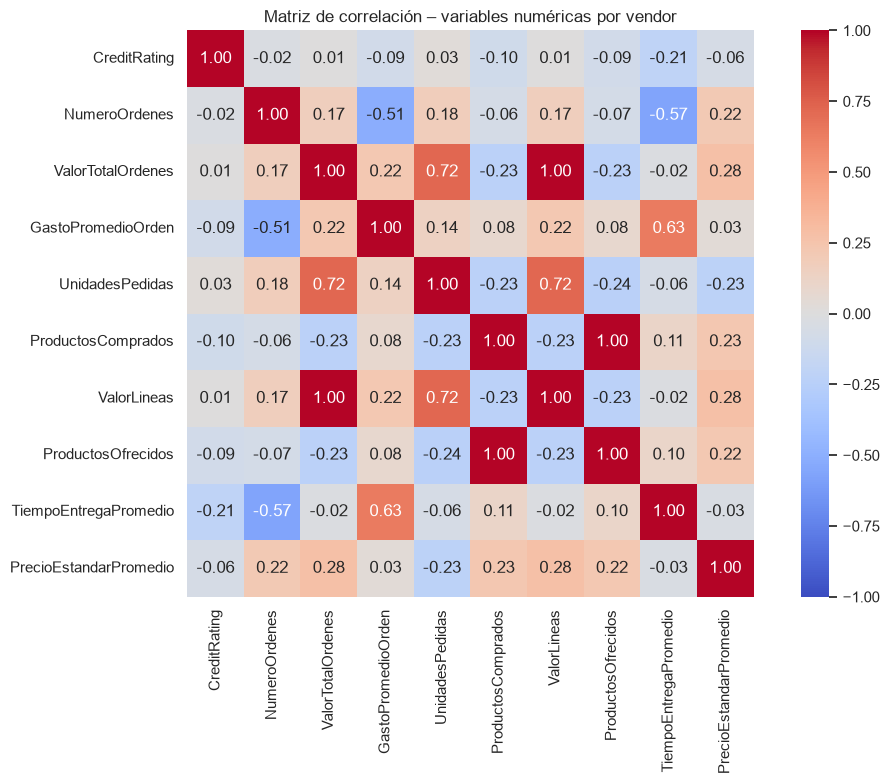

,Variable 1,Variable 2,Correlación
26,ValorTotalOrdenes,ValorLineas,1.00
57,ProductosComprados,ProductosOfrecidos,1.00
46,UnidadesPedidas,ValorLineas,0.72
24,ValorTotalOrdenes,UnidadesPedidas,0.72
38,GastoPromedioOrden,TiempoEntregaPromedio,0.63
18,NumeroOrdenes,TiempoEntregaPromedio,-0.57
13,NumeroOrdenes,GastoPromedioOrden,-0.51
29,ValorTotalOrdenes,PrecioEstandarPromedio,0.28
69,ValorLineas,PrecioEstandarPromedio,0.28
47,UnidadesPedidas,ProductosOfrecidos,-0.24


In [19]:
num = consol.select_dtypes("number").drop(columns=[c for c in consol.columns if c.lower().endswith("id")], errors="ignore")
corr = num.corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True)
plt.title("Matriz de correlación – variables numéricas por vendor"); plt.tight_layout(); plt.show()

pares = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().rename("Correlación").reset_index()
pares.columns = ["Variable 1","Variable 2","Correlación"]
display(pares.reindex(pares["Correlación"].abs().sort_values(ascending=False).index).head(10))

**Conclusión:** (matriz calculada sobre los 88 vendors con datos)

- **Redundancia total.** ValorTotalOrdenes y ValorLineas (r = 1.00) miden prácticamente lo mismo; igual ProductosComprados y ProductosOfrecidos (r = 1.00). No deben usarse juntas.
- **Correlación alta.** UnidadesPedidas con ValorTotalOrdenes y con ValorLineas (r = 0.72): los vendors que piden más unidades tienden a gastar más.
- **NumeroOrdenes vs ValorTotalOrdenes: r = 0.17.** Tener más órdenes casi no implica mayor monto, así que las dos variables aportan información distinta y no son redundantes entre sí.
- **Correlaciones moderadas.** NumeroOrdenes con TiempoEntregaPromedio (−0.57) y con GastoPromedioOrden (−0.51); GastoPromedioOrden con TiempoEntregaPromedio (0.63). La relación con GastoPromedioOrden es en parte esperable, porque probablemente es el monto dividido entre el número de órdenes.
- **Correlaciones débiles.** CreditRating y PrecioEstandarPromedio no se relacionan con el resto (|r| ≤ 0.28).

**Recomendación para el clustering:** usar ValorTotalOrdenes (tamaño en monto) y NumeroOrdenes (actividad), como define el sprint; su baja correlación evita duplicar información. Descartar ValorLineas y ProductosOfrecidos por redundancia. Advertencia: NumeroOrdenes casi no varía entre la mayoría de vendors (50–51), así que la segmentación quedará dominada por el monto.

## 6. Tabla de calidad de datos y decisiones de limpieza

In [20]:
tabla_calidad = pd.concat([pd.DataFrame(calidad, columns=["Tabla","Problema","Cantidad","% de filas"]), anom], ignore_index=True)
display(tabla_calidad)

,Tabla,Problema,Cantidad,% de filas
0,ProductVendor,Valores faltantes en LastReceiptCost,7,1.50
1,ProductVendor,Valores faltantes en LastReceiptDate,7,1.50
2,ProductVendor,Valores faltantes en OnOrderQty,311,66.60
3,Consolidado,Valores faltantes en NumeroOrdenes,18,16.98
4,Consolidado,Valores faltantes en ValorTotalOrdenes,18,16.98
5,Consolidado,Valores faltantes en GastoPromedioOrden,18,16.98
6,Consolidado,Valores faltantes en UltimaOrden,18,16.98
7,Consolidado,Valores faltantes en UnidadesPedidas,18,16.98
8,Consolidado,Valores faltantes en ProductosComprados,18,16.98
9,Consolidado,Valores faltantes en ValorLineas,18,16.98


**Decisiones de limpieza:**
- **18 vendors sin órdenes** (16.98 %): no tienen monto ni número de órdenes, así que no se pueden segmentar. Se excluyen del dataset de clustering y se conservan en el consolidado original. Dataset limpio: **88 vendors** (`data/processed/purchasing_clean.csv`).
- **1 orden con TotalDue ≤ 0** (0.02 %, orden 6013): es una orden pendiente y sin valor, no una compra real. Su impacto es mínimo (suma 0 al monto y 1 al conteo de un solo vendor). Se documenta como anomalía; puede excluirse filtrando `TotalDue > 0` en el script de consolidación.
- **Outliers de monto:** se conservan; son vendors grandes legítimos y forman el segmento "Grandes".
- **Falsos outliers** (CreditRating, RevisionNumber, Status, RejectedQty): no requieren tratamiento, son variables categóricas o casi constantes.
- **Faltantes en ProductVendor:** no se tratan, esas columnas no entran al clustering.
- **Fechas como texto:** conversión a `datetime` pendiente, solo necesaria si se hace análisis temporal.

**Limitación a revisar con el equipo:** el 2.1 % de las órdenes (86) está rechazada (Status = 3) y el 5.8 % (233) está pendiente (Status = 1). Si el consolidado suma todas las órdenes sin filtrar por Status, el monto de algunos vendors podría estar sobreestimado. Confirmado con `consolidate_data.py`.

**Estado para Molina:** los datos están listos para el clustering. Usar `purchasing_clean.csv`, con ValorTotalOrdenes y NumeroOrdenes como variables principales.

In [21]:
clean = consol.dropna(subset=["NumeroOrdenes","ValorTotalOrdenes"]).copy()
clean.to_csv(PROC/"purchasing_clean.csv", index=False)
print(f"Dataset limpio para clustering: {clean.shape[0]} vendors (de {consol.shape[0]}). Guardado en data/processed/purchasing_clean.csv")

Dataset limpio para clustering: 88 vendors (de 106). Guardado en data/processed/purchasing_clean.csv
